In [1]:
import pickle
from tqdm.notebook import tqdm
import pandas as pd
import wandb
import numpy as np
import matplotlib.pyplot as plt


api = wandb.Api()

import wandb

In [2]:


# Log in (if not already logged in)
wandb.login()

# Set your project and entity info
entity = "Long_Memory_Arena"  # Replace with your team/username if different
project = "Testing"

# Initialize the API
api = wandb.Api()

# Get the runs from the project
runs = api.runs(f"{entity}/{project}")

# Loop through runs and get their artifacts
for run in tqdm(runs):
    print(f"Run: {run.name}")
    


wandb: Using wandb-core as the SDK backend.  Please refer to https://wandb.me/wandb-core for more information.


  0%|          | 0/1 [00:00<?, ?it/s]

Run: Small_lr_aaBs


In [ ]:
def download_artifacts(run_path):
    run = api.run(f"{run_path}")
    print(f"Run: {run.name}")
    for artifact in tqdm(run.logged_artifacts()):
        print(f" - Artifact: {artifact.name}")
        # You can also download it
        artifact_dir = artifact.download(root=f"artifact/{run.name}")
        print(f"   Downloaded to: {artifact_dir}")

download_artifacts(f"Long_Memory_Arena/Testing/t4vf6xvw")

In [3]:
from pathlib import Path
import ast
from tqdm.notebook import tqdm
from natsort import natsorted
import numpy as np
import os
import json

base_dir = f'./notebooks/Dataset/SSM_eig/artifact/{run.name}'  # Change this to your actual path
all_complex_lists = []
for npz_path in tqdm(natsorted(list(Path(base_dir).glob("*.npz")))):
    if npz_path.exists():
        try:
            data = np.load(npz_path)
            real = data['real']
            imag = data['imag']
            complex_array = real + 1j * imag
            all_complex_lists.append(complex_array)
        except Exception as e:
            print(f"Failed to load {npz_path.name}: {e}")
    else:
        print(f"Missing file: {npz_path}")

# Stack into a single numpy array if you want
all_complex_lists = np.array(all_complex_lists)
all_complex_lists = np.exp(all_complex_lists.reshape(all_complex_lists.shape[0],-1))

  0%|          | 0/440 [00:00<?, ?it/s]

In [4]:
import numpy as np
import matplotlib.pyplot as plt

def plot_hist(epoch, bins=5):
    # Get complex numbers for the given epoch
    complex_vals = all_complex_lists[epoch]

    # Compute modulus and angle
    moduli = np.abs(complex_vals)                     # |z|
    angles = np.mod(np.angle(complex_vals), 2 * np.pi)  # angle in [0, 2π]
    real_parts = [c.real for c in complex_vals]
    imag_parts = [c.imag for c in complex_vals]

    fig, axes = plt.subplots(1, 3, figsize=(12, 3))  # 1 row, 3 columns

    # Set ranges
    modulus_range = (0, 1)
    angle_range = (0, 2 * np.pi)
    y_range = (0, 14)

    # Add overall title
    fig.suptitle(f"Histogram and Complex Plane (Epoch {epoch})", fontsize=14)

    # Modulus histogram
    axes[0].hist(moduli, bins=bins, range=modulus_range)
    axes[0].set_title("Modulus (|z|)")
    axes[0].set_xlabel("Value")
    axes[0].set_ylabel("Frequency")
    axes[0].set_ylim(y_range)

    # Angle histogram
    axes[1].hist(angles, bins=bins, range=angle_range)
    axes[1].set_title("Angle (arg(z))")
    axes[1].set_xlabel("Radians")
    axes[1].set_ylabel("Frequency")
    axes[1].set_ylim(y_range)

    # Complex plane scatter plot
    axes[2].scatter(real_parts, imag_parts, alpha=0.7)
    axes[2].set_title("Complex Plane")
    axes[2].set_xlabel("Real")
    axes[2].set_ylabel("Imaginary")
    axes[2].grid(True)
    axes[2].set_aspect('equal', adjustable='box')  # <<< Force 1:1 ratio here
    axes[2].set_xlim(-1, 1)                        # x-axis fixed
    axes[2].set_ylim(-1, 1)   
    plt.tight_layout(rect=[0, 0, 1, 0.92])
    plt.show()


In [ ]:
for i in range(60,140,1):
    plot_hist(i, bins = 6)

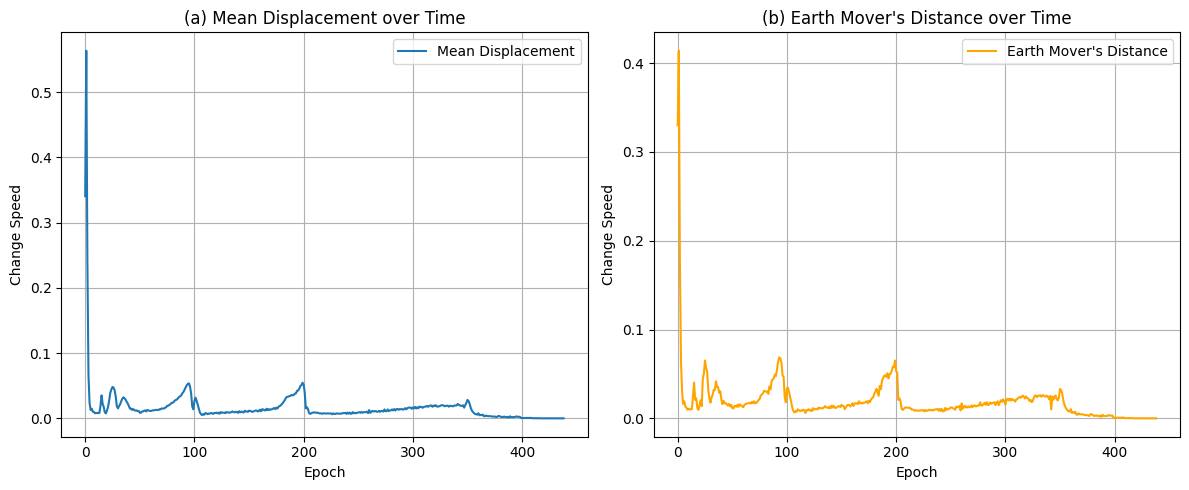

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import wasserstein_distance
from tqdm import tqdm

# Assume you already have:
# all_complex_lists: shape (num_epochs, num_points)

num_epochs = len(all_complex_lists)

# (a) Mean Displacement (Euclidean Distance) between successive epochs
mean_speeds = []

for i in range(num_epochs - 1):
    points_now = all_complex_lists[i]
    points_next = all_complex_lists[i + 1]

    # difference between corresponding points
    diffs = points_next - points_now  # still complex numbers
    norms = np.abs(diffs)  # abs() of complex = Euclidean norm
    mean_norm = np.mean(norms)

    mean_speeds.append(mean_norm)

# (b) Earth Mover's Distance (EMD) separately on real and imag parts
emd_speeds = []

for i in range(num_epochs - 1):
    points_now = all_complex_lists[i]
    points_next = all_complex_lists[i + 1]

    real_now = points_now.real
    imag_now = points_now.imag
    real_next = points_next.real
    imag_next = points_next.imag

    emd_real = wasserstein_distance(real_now, real_next)
    emd_imag = wasserstein_distance(imag_now, imag_next)

    emd_total = emd_real + emd_imag
    emd_speeds.append(emd_total)

# Plotting
epochs = np.arange(num_epochs - 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, mean_speeds, label="Mean Displacement")
plt.xlabel("Epoch")
plt.ylabel("Change Speed")
plt.title("(a) Mean Displacement over Time")
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, emd_speeds, label="Earth Mover's Distance", color='orange')
plt.xlabel("Epoch")
plt.ylabel("Change Speed")
plt.title("(b) Earth Mover's Distance over Time")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()
